# Generative Music
##### Boate Boetes & Nynke Keegstra

Om de muziek te genereren hebben we wat anders nodig dan noten, hiermee kan een computer net wat minder handig werken, dus zetten we de noten van een muziekstuk om naar tekst, dit is een stuk makkelijker voor een computer en dus ook voor deze opdracht. <br/>
Hiervoor wordt de bibliotheek music21 gebruikt. <br/>
Dit probleem kan worden beschreven als een soort classificatie probleem omdat we eigenlijk muzieknoot na muzieknoot willen voorspellen, hierbij kan dus gekozen worden uit dan een groep van muzieknoten, dit valt dus te vergelijken met een soort klein LLM voor muziek.

In [1]:
# voor het installeren van de bibliotheek, hoeft maar 1 keer gerund te worden
#%pip install music21

In [2]:
from fractions import Fraction

from music21 import converter, tempo
from music21.note import Note, Unpitched
from music21.stream import Stream
from music21.converter import parse
from music21 import *

In [3]:
# Voor dit project gebruiken we ook de volgende functies:

# Voor muziek omzetten naar tekst

def stream_to_string(stream):
    tokens = []
    last_offset = 0

    flat_stream = stream.flatten()
    
    tempo_marks = flat_stream.getElementsByClass(
        tempo.MetronomeMark
    )

    if len(tempo_marks) > 0 and tempo_marks[0].number:
        bpm = tempo_marks[0].number
    else:
        bpm = 120

    tokens.append("bpm_{}".format(bpm))

    for n in flat_stream.notes:
        delta = n.offset - last_offset
        duration = n.duration.components[0].type
        last_offset = n.offset

        if delta:
            tokens.append("w_{}".format(delta))

        if isinstance(n, (Note, Unpitched)):
            notes = [n]
        elif hasattr(n, "notes"):
            notes = n.notes
        else:
            continue

        for i in notes:
            if isinstance(i, Note):
                tokens.append("n_{}_{}".format(i.pitch.midi, duration))
            elif isinstance(i, Unpitched):
                tokens.append("n_unpitched_{}".format(duration))

    return ' '.join(tokens)

In [4]:
# hetzelfde maar dan gelijk met een file
def file_to_string(file_path):
    score = parse(file_path, quantizePost=True, quarterLengthDivisors=(4,3))
    return stream_to_string(score)

In [5]:
# om het stuk tekst weer om te zetten naar muziek, deze code heb ik aangepast, slaat nu eerst de unpitched noten over
def string_to_stream(tokens):
    stream = Stream()
    time = 0
    bpm = 120

    for i in tokens.split():

        if i.startswith('bpm_'):
            bpm = float(i[4:])

        elif i.startswith('w_'):
            time += float(i[2:])

        elif i.startswith('n_'):
            note, duration = i[2:].split('_', 1)

            if note == 'unpitched':
                continue

            n = Note(int(note))
            n.duration.type = duration
            stream.insert(time, n)

    stream.insert(0, tempo.MetronomeMark(number=bpm))

    return stream

### Data Inladen
We willen verschillende nummers hebben van de artiest die we kiezen, aangezien we nog geen artiest hebben gekozen en een van mijn favoriete artiesten Radiohead is, heb ik alsnog uitgeprobeerd om een stuk muziek van Radiohead te importeren, hierbij heb ik online een MIDI file gevonden die alleen de piano heeft van het nummer "No Surprises" en heb ik daarvan de data ingeladen met behulp van de functies, ik heb wel de stream_to_string functie moeten aanpassen omdat alles in het project bestand flink verouderd is.

In [6]:
tekst = file_to_string("C:/Users/boate/Downloads/No Surprises -Radiohead (Piano).mid")
#tekst = file_to_string("C:/Users/Nynke/Documents/Machine_learning/Generative_Music_Radiohead/Radiohead_-_No_Surprises.mid")

In [7]:
print(tekst[:1000])

bpm_78 n_81_eighth n_41_half w_0.5 n_72_eighth w_0.5 n_77_eighth w_0.5 n_72_eighth w_0.5 n_81_16th n_41_16th w_0.5 n_72_eighth n_41_quarter w_0.5 n_77_eighth w_0.5 n_72_eighth w_0.5 n_81_eighth n_41_half w_0.5 n_72_eighth w_0.5 n_77_eighth w_0.5 n_72_eighth w_0.5 n_70_eighth n_46_eighth w_0.5 n_73_eighth w_0.25 n_46_eighth w_0.25 n_77_eighth w_0.5 n_79_eighth n_45_eighth w_0.5 n_81_eighth n_41_half w_0.5 n_72_eighth w_0.5 n_77_eighth w_0.5 n_72_eighth w_0.5 n_81_16th n_41_16th w_0.5 n_72_eighth n_41_quarter w_0.5 n_77_eighth w_0.5 n_72_eighth w_0.5 n_81_eighth n_41_half w_0.5 n_72_eighth w_0.5 n_77_eighth w_0.5 n_72_eighth w_0.5 n_70_eighth n_46_eighth w_0.5 n_73_eighth w_0.25 n_46_eighth w_0.25 n_77_eighth w_0.5 n_79_eighth n_45_eighth w_0.5 n_81_eighth n_41_half n_65_quarter n_60_quarter n_53_quarter w_0.5 n_72_eighth w_0.5 n_77_eighth n_65_eighth n_60_eighth n_53_eighth w_0.5 n_72_eighth w_0.25 n_65_16th n_60_16th n_53_16th w_0.25 n_81_eighth n_41_eighth n_65_eighth n_60_eighth n_53

In [8]:
stream = string_to_stream(tekst)
stream.show('midi')

Het proces van nummers verzamelen die alleen piano hebben en voor de rest niks, is heel erg lastig, het is niet consistent te vinden en als je er één hebt gevonden dan moet je ervoor betalen of wat anders doms.

### EDA
Deze EDA gaat er anders uitzien dan andere EDA's omdat we met een speciaal soort data bezig zijn, deze EDA gaat dus vooral bestaan uit wat de string van een nummer nou eigenlijk betekend, hiermee wordt een stuk tekst zoals hierboven mee bedoeld. <br/>
Met de EDA kunnen we vooral kijken naar een wordcloud, dit laat zien welke woorden (noten) het meest voorkomen.

In [9]:
from music21 import pitch

midi_nummer = 53

noot = pitch.Pitch()
noot.midi = midi_nummer

print(noot.nameWithOctave)

F3


Als er een muziekstuk omgezet wordt naar tekst, dit is nodig omdat we dan met machine learning nieuwe muziek kunnen maken, dan zijn er allemaal rare tekentjes, maar die rare tekentjes zijn allemaal onder te verdelen in maar 2 gebieden. <br/> <br/>
het eerste gebied zijn de noten, je ziet stukjes tekst staan zoals: 'n_81_eighth', 'n_41_16th' en 'n_65_eighth', de 'n' staat voor dat er een noot wordt gespeeld, het cijfer daarachter zegt welke noot, 81 staat gelijk aan de noot A5, en 41 staat gelijk aan F2 (hierboven in het stukje code zegt welk cijfer gelijk staat aan welke muzieknoot). Het laatste wat aan deze stukjes tekst verteld hoe lang een noot moet worden gespeeld, eigth zegt dat de noot voor 1/8 beat moet wordeng gespeeld en 16th zegt dat de noot voor 1/16 beat moet worden gespeeld. <br/> <br/>
het tweede gebied is een stuk simpeler, die bestaat uit stukjes tekst zoals 'w_0.5' en 'w_0.25' dit geeft aan hoe lang het moet wachten, bij w_0.5 moet er een halve beat gewacht worden, en bij w_0.25 moet er 1/4 beat gewacht worden. <br/>
Dan als laatst, er staat helemaal aan het begin een bpm, dit verteld in hoeveel 'beats per minute' het nummer moet worden gespeeld.

In [10]:
# %pip install wordcloud

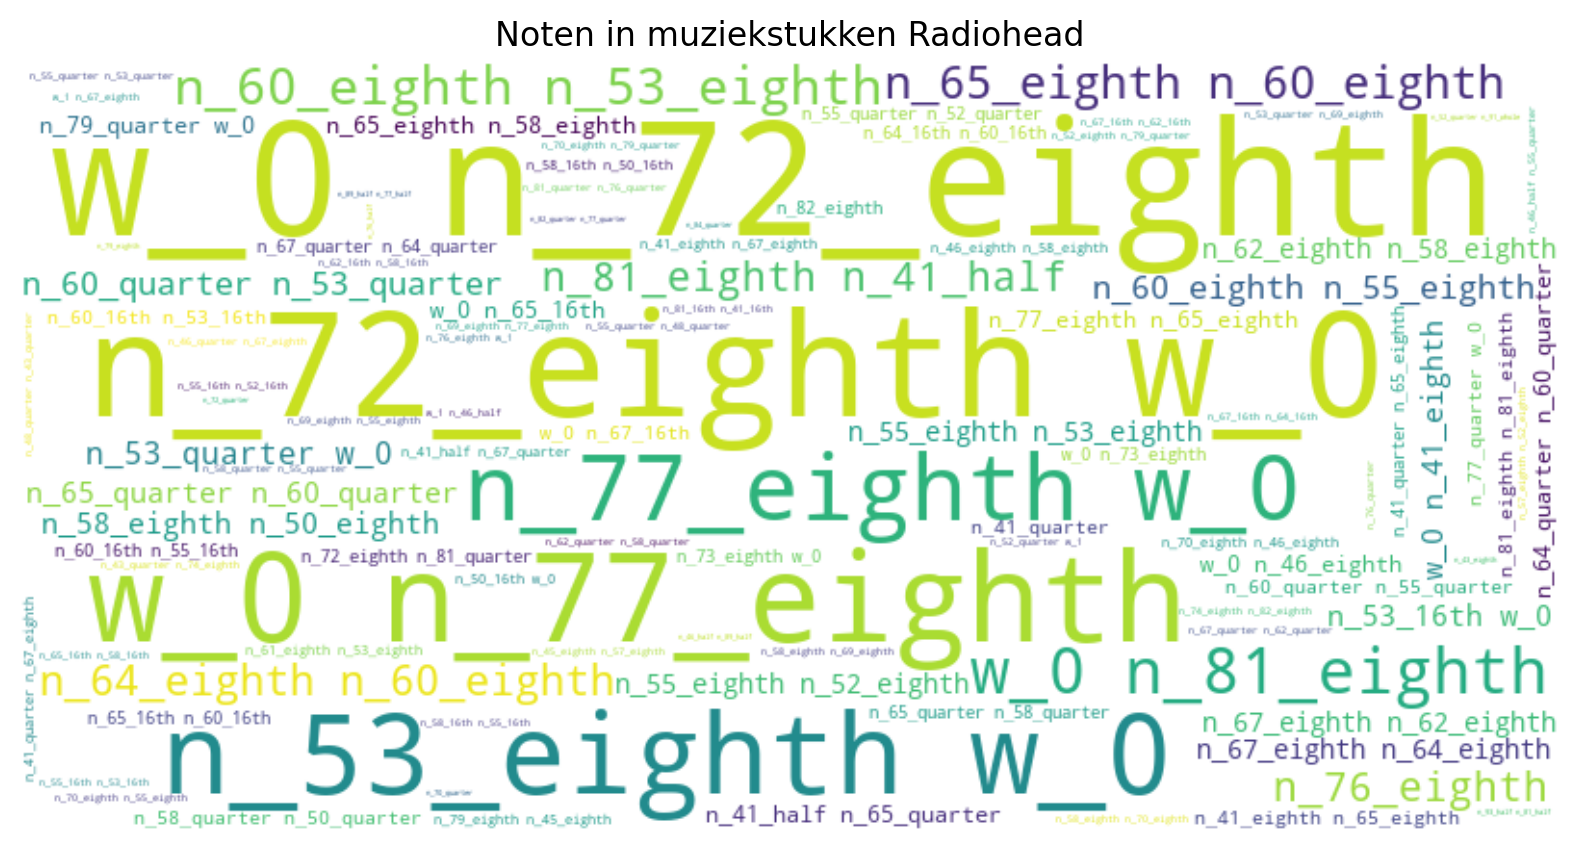

In [11]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(tekst)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  
plt.title("Noten in muziekstukken Radiohead")
plt.show()

Het meeste wat in de wordcloud voorkomt, zijn de noten 'n_72_eighth', 'n_77_eighth' en 'n_53_eighth', dit zijn de muzieknoten C5, F5 en F3.

### Modellen
1. Markov keten
2. Recurrent Neural Network (LSTM)
3. Transformer Architecture

### 1. Markov keten algoritme

**Wat is een Markov-keten?**

Een Markov-keten is een simpele manier om te raden wat er hierna komt. Het model kijkt daarvoor alleen naar het laatste stukje dat net geweest is. Wat er daarvoor gebeurde, doet er niet toe.

Een voorbeeld is het weer. Is het vandaag zonnig, dan is het morgen waarschijnlijk weer zonnig. Regent het vandaag, dan is de kans op regen morgen groter dan normaal. Om het weer van morgen te raden, kijken we dus alleen naar vandaag. Doen we dat steeds opnieuw, dan krijgen we een hele reeks dagen die er echt uitziet.

**Hoe werkt dit bij muziek?**

We hebben het muziekstuk omgezet naar tekst. Elk stukje van die tekst noemen we een *token*, bijvoorbeeld een noot (`n_81_eighth`) of een korte pauze (`w_0.5`).

Het model leert uit het nummer welk token er meestal na welke tokens komt:
1. We lopen door het nummer heen.
2. Bij elk stukje schrijven we op welk token daarna kwam.
3. Komt een token vaker voor na een bepaald stukje, dan staat het vaker in de lijst. Het heeft dan een grotere kans om gekozen te worden.

Hoeveel tokens het model tegelijk onthoudt, noemen we de *geheugengrootte* (in de code: `state_size`). Is die 2, dan kijkt het model naar de laatste twee tokens om het volgende token te kiezen.

**Nieuwe muziek maken**

1. We beginnen met een willekeurig stukje uit het nummer.
2. We kiezen willekeurig een token dat daarna kan komen.
3. We voegen dat token toe en doen dit opnieuw, tot de muziek lang genoeg is.
4. Daarna zetten we de tekst weer om naar muziek, zodat we hem kunnen afspelen.

**Wat is een goede geheugengrootte?**

- Is het geheugen **te klein**, dan klinkt de muziek rommelig. Het model onthoudt te weinig.
- Is het geheugen **te groot**, dan lijkt de muziek te veel op het origineel. Het model kopieert dan hele stukken.

We proberen daarom verschillende groottes uit en luisteren welke het mooiste klinkt.

**Wat hebben we aangepast?**

Het voorbeeld van Healey is gemaakt voor zinnen. Een zin begint daar met een hoofdletter en eindigt met een punt. Muziek heeft dat niet, dus we hebben twee dingen veranderd:
- **Begin:** we kiezen een willekeurig stukje uit het nummer, in plaats van een woord met een hoofdletter.
- **Einde:** we stoppen niet bij een punt, maar als de muziek lang genoeg is.

*Bron: https://healeycodes.com/generating-text-with-markov-chains*

In [12]:
# uitvoering van het markov algoritme
# stap 1: het model bouwen
import random

def bouw_markov_model(tekst, geheugen): 
    # Het model onthoudt bij elk stukje (van 'geheugen' tokens) welke tokens daarna kwamen
    tokens = tekst.split()
    model = {} 
    for i in range(geheugen, len(tokens)): 
        vorige = ' '.join(tokens[i - geheugen:i])  # het stukje ervoor
        volgende = tokens[i]                       # het token dat daarna kwam
        if vorige in model: 
            model[vorige].append(volgende)
        else: 
            model[vorige] = [volgende]
    return model

In [13]:
# de nieuwe muziek maken
def maak_muziek_markov(model, geheugen, minimale_lengte): 
    # Maakt nieuwe muziektekst die minstens de minimale lengte tokens lang is. 

    def kies_begin(): 
        # dit kiest een willekeurig beginstukje uit het model
        return random.choice(list(model.keys())).split(' ')

    muziek = kies_begin()
    while True: 
        laatste = ' '.join(muziek[-geheugen:])  # de laatste tokens

        if laatste not in model: 
            # dit stukje komt nergens een vervolg: begin met een neiuw stukje
            muziek = muziek + kies_begin()
            continue 

        # kies willekeurig een token dat hierna kan komen
        muziek.append(random.choice(model[laatste]))

        # stop als de muziek lang genoeg is en we eindigen op een noot
        if len(muziek) >= minimale_lengte and muziek[-1].startswith('n_'): 
            break

    return ' '.join(muziek)

In [14]:
# model bouwen en muziek maken
geheugen = 2 #kijkt naar dit aantal vorige tokens
model = bouw_markov_model(tekst, geheugen)
nieuwe_muziek_markov = maak_muziek_markov(model, geheugen, minimale_lengte=200)
print(nieuwe_muziek_markov)

n_45_eighth w_1.5 n_81_eighth n_41_half n_76_half n_65_quarter n_60_quarter n_53_quarter w_0.5 n_72_eighth n_81_eighth w_0.5 n_72_eighth n_81_quarter w_0.5 n_67_eighth n_76_eighth w_0.5 n_77_quarter w_0.25 n_67_16th n_62_16th n_58_16th n_55_16th n_53_16th w_0.25 n_41_eighth n_65_eighth n_58_eighth n_50_eighth w_0.5 n_67_quarter n_64_quarter n_60_quarter n_55_quarter n_52_quarter w_1.0 n_46_half n_55_quarter n_48_quarter n_43_quarter n_74_eighth n_82_eighth w_0.5 n_72_eighth w_0.5 n_77_eighth w_0.5 n_72_eighth w_0.5 n_81_eighth n_81_eighth n_76_eighth w_0.5 n_77_quarter w_0.25 n_67_16th n_64_16th n_60_16th n_55_16th n_52_16th w_0.25 n_41_eighth n_67_eighth n_58_eighth n_72_eighth n_55_eighth n_53_eighth w_0.5 n_79_quarter n_72_eighth w_0.25 n_41_eighth n_65_eighth n_60_eighth n_53_eighth w_0.5 n_70_eighth n_79_quarter w_0.25 n_67_16th n_64_16th n_60_16th n_55_16th n_52_16th w_0.25 n_41_eighth n_64_eighth n_60_eighth n_55_eighth n_52_eighth w_0.5 n_41_quarter n_67_eighth n_64_eighth n_60

In [15]:
# afspelen
stream = string_to_stream(nieuwe_muziek_markov)
stream.show('midi')